# Create a Simple Reflex-Based Lunar Lander Agent

In this example, we will use Gymnasium, an environment to train agents via reinforcement learning (RL). We will not use RL here but just use the environment with a custom simple reflex-based agent. 

## Install Gymnasium

The documentation for Gymnasium is available at https://gymnasium.farama.org/ 

Steps:
1. Create a new folder and open it with VS Code and install all needed Python Extensions in VS Code.
2. Create a new virtual environment (CTRL-Shift P Python Create Environment...)
3. I needed to install swig and the Python C++ headers on WSL2 via the terminal
    * `sudo apt install swig`
    * `sudo apt-get install python3-dev` 
4. Install python libraries for gymnasium with the needed extras

In [1]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
%pip install -q "swig>=4,<5" "gymnasium[box2d,classic-control]>=1.0,<2"

Additional installs for screen capturing so environment visualizations can be converted to embedded videos.
For recording videos, I had to install
    
* `sudo apt-get install xvfb ffmpeg`

Additional python packages for screen capturing.

In [2]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
%pip install -q "pyvirtualdisplay>=3,<4" "gymnasium[other]>=1.0,<2"

## The Lunar Lander Environment 

![Luna Lander image](https://gymnasium.farama.org/_images/lunar_lander.gif)

The documentation of the environment is available at: https://gymnasium.farama.org/environments/box2d/lunar_lander/

* Performance Measure: A reward of -100 or +100 points for crashing or landing safely respectively. We do not use 
  intermediate rewards here.

* Environment: This environment is a classic rocket trajectory optimization problem. A ship needs to land safely. The space is **continuous** with
  x and y coordinates in the range [-2.5, 2.5]. The landing pad is at coordinate (0,0).

* Actuators:  According to Pontryagin’s
  maximum principle, it is optimal to fire the engine at full throttle or turn it off. This is the reason why this environment has discrete actions: engine on or off. There are four discrete actions available:

    - 0: do nothing
    - 1: fire left orientation engine
    - 2: fire main engine
    - 3: fire right orientation engine

* Sensors: Each observation is an 8-dimensional vector: the coordinates of the lander in x & y, its linear velocities in x & y, its angle, its angular velocity, and two booleans that represent whether each leg is in contact with the ground or not.

The different ranges/settings of the environment can be queried.

## Import thư viện

- `gymnasium` (đặt tên là`gym`): thư viện cung cấp môi trường mô phỏng để huấn luyện và đánh giá tác tử,  dùng để tạo môi trường Lunar Lander.
- `numpy` (đặt tên là `np`): thư viện tính toán số học trên mảng
- `np.set_printoptions(precision=2)`: Giới hạn tối đa 2 chữ số thập phân sau dấu phẩy khi in mảng numpy

In [3]:
import gymnasium as gym
import numpy as np
np.set_printoptions(precision=2)

## Khảo sát môi trường Lunar Lander

Hàm `query_environment(name)` với biến đầu vào là `name`:
Dùng để in các thông tin như:
- **Action Space:** không gian hành động. `Discrete(4)` nghĩa là có 4 hành động rời rạc: 0 - không làm gì, 1 - động cơ trái, 2 - động cơ chính, 3 - động cơ phải.
- **Observation Space:** không gian quan sát, là vector 8 chiều liên tục gồm tọa độ (x, y), vận tốc (x, y), góc nghiêng, vận tốc góc và hai cờ tiếp xúc mặt đất của hai chân.
- **Max Episode Steps:** số bước tối đa của một episode, sau đó môi trường tự kết thúc (truncated).
- **Nondeterministic:** cho biết môi trường có tính ngẫu nhiên hay không.
- **Reward Threshold:** ngưỡng reward mà môi trường coi là "đã giải được" bài toán.

Dòng in `Reward Range` bị comment vì thuộc tính `env.reward_range` không còn được hỗ trợ trong các phiên bản Gymnasium mới.

Sau khi in xong, `env.close()` giải phóng tài nguyên của môi trường.

Chạy hàm `query_environment(name)` với biến đầu vào là môi trường `LunarLander-v3` sẽ in ra được các cấu hình định nghĩa sẵn của môi trường


In [15]:
def query_environment(name):
    env = gym.make(name)
    print(f"Action Space: {env.action_space}")
    print(f"Observation Space: {env.observation_space}")
    print(f"Max Episode Steps: {env.spec.max_episode_steps}")
    print(f"Nondeterministic: {env.spec.nondeterministic}")
   # print(f"Reward Range: {env.reward_range}")
    print(f"Reward Threshold: {env.spec.reward_threshold}")
    env.close()

query_environment("LunarLander-v3")

Action Space: Discrete(4)
Observation Space: Box([ -2.5   -2.5  -10.   -10.    -6.28 -10.    -0.    -0.  ], [ 2.5   2.5  10.   10.    6.28 10.    1.    1.  ], (8,), float32)
Max Episode Steps: 1000
Nondeterministic: False
Reward Threshold: 200



Gymnasium environments are implemented as classes with a `make` method to create the environment, a `reset` method, and a `step` method to execute an action.
To use it with an agent function that expects percepts and returns an action, we need write glue code that connects the environment with the agent function.

## Chạy một episode

Hàm `run_episode(agent_function, env, ...)` cho một tác tử chạy trọn một episode trong môi trường và trả về **reward** của bước cuối episode,tức +100 nếu hạ cánh an toàn và -100 nếu rơi.

**Tham số:**
- `agent_function`: hàm của tác tử, nhận observation (vector 8 chiều) và trả về một action rời rạc (0-3).
- `env`: môi trường Gymnasium đã tạo bằng `gym.make(...)`.
- `max_steps`: số bước tối đa của một episode (mặc định 1000).
- `verbose`: nếu `True`, in observation, action ở mỗi bước và reward  của bước cuối episode.
- `render`: nếu `True`, hiển thị môi trường (cần tạo env với `render_mode="human"`).
- `seed`: tùy chọn, đặt seed cho `env.reset` để kết quả có thể lặp lại.

**Luồng thực hiện:**
1. `env.reset()` đưa môi trường về trạng thái ban đầu và trả về observation đầu tiên.
2. Ở mỗi bước, tác tử chọn action dựa trên observation hiện tại, sau đó `env.step(action)` thực hiện action và trả về observation mới, reward của bước đó, cờ `terminated`, cờ `truncated` và `info`.
3. Episode dừng khi tàu đã hạ cánh hoặc rơi (`terminated`), khi hết giới hạn thời gian (`truncated`), hoặc khi đủ `max_steps`.


In [41]:
from random import seed


def run_episode(agent_function, env, max_steps=1000, verbose = True, render = True):
    """Run one episode in the environment using the provided agent."""

    # Reset the environment to generate the first observation (use seed=42 in reset to get reproducible results)
    observation,info= env.reset()

    # run one episode
    for _ in range(max_steps):
        # call the agent function to select an action
        action = agent_function(observation)

        if verbose:
            print (f"Obs: {observation} -> Action: {action}")

        # step: execute an action in the environment
        observation, reward, terminated, truncated, info = env.step(action)

        # render the environment
        if render:
            env.render()

        if terminated or truncated:
            if verbose:
                print(f"Final Reward: {reward}")
            break
    
    return reward

## Example: A Random Agent

We randomly return one of the actions. The environment accepts the integers 0-3.


In [12]:
def random_agent_function(observation): 
    """A random agent that selects actions uniformly at random. It ignores the observation."""
    return np.random.choice([0, 1, 2, 3], p=[0.25, 0.25, 0.25, 0.25])

Run an episode.

In [21]:
env = gym.make("LunarLander-v3", render_mode="human")

run_episode(random_agent_function, env)

env.close()

Obs: [ 0.    1.42  0.23  0.32 -0.   -0.05  0.    0.  ] -> Action: 3
Obs: [ 0.    1.42  0.24  0.29 -0.01 -0.08  0.    0.  ] -> Action: 3
Obs: [ 0.01  1.43  0.25  0.27 -0.01 -0.13  0.    0.  ] -> Action: 1
Obs: [ 0.01  1.44  0.24  0.24 -0.02 -0.08  0.    0.  ] -> Action: 0
Obs: [ 0.01  1.44  0.24  0.22 -0.02 -0.08  0.    0.  ] -> Action: 2
Obs: [ 0.01  1.45  0.23  0.25 -0.03 -0.09  0.    0.  ] -> Action: 3
Obs: [ 0.02  1.45  0.24  0.22 -0.03 -0.12  0.    0.  ] -> Action: 0
Obs: [ 0.02  1.46  0.24  0.2  -0.04 -0.12  0.    0.  ] -> Action: 0
Obs: [ 0.02  1.46  0.24  0.17 -0.04 -0.12  0.    0.  ] -> Action: 3
Obs: [ 0.02  1.46  0.25  0.14 -0.05 -0.16  0.    0.  ] -> Action: 2
Obs: [ 0.03  1.47  0.24  0.16 -0.06 -0.17  0.    0.  ] -> Action: 3
Obs: [ 0.03  1.47  0.25  0.13 -0.07 -0.21  0.    0.  ] -> Action: 2
Obs: [ 0.03  1.47  0.26  0.14 -0.08 -0.2   0.    0.  ] -> Action: 1
Obs: [ 0.03  1.48  0.25  0.11 -0.09 -0.17  0.    0.  ] -> Action: 1
Obs: [ 0.04  1.48  0.24  0.09 -0.1  -0.13  0.   

Gymnasium displays environments using `render()` method on the local display. Headless installations like Google Colab do not have a display, but the output can be captured using a virtual display as a video and then add the video to the notebook.

We need to start a virtual display.

Now we can use wrappers for the environment to record the display. The functions are provided in
[gymnasium_display_recorder.py].



In [22]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("gymnasium_display_recorder.py", 
         "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Agents/")

Run experiments.

In [23]:
import gymnasium_display_recorder as dr

env = dr.gym_make('LunarLander-v3', 'LL1', render_fps=30)
run_episode(random_agent_function, env, verbose=False)
env.close()

dr.show('LL1')

/usr/local/lib/python3.12/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"


## A Simple Reflex-Based Agent

To make the code easier to read, we use enumerations for actions (integers) and observations (index in the observation vector).

**`Act`: các hành động (actuators)**

| Tên | Giá trị | Ý nghĩa |
|---|---|---|
| `NO_OP` | 0 | Không làm gì |
| `LEFT` | 1 | Bật động cơ định hướng trái |
| `MAIN` | 2 | Bật động cơ chính (đẩy lên) |
| `RIGHT` | 3 | Bật động cơ định hướng phải |

**`Obs`: vị trí (index) trong vector quan sát 8 chiều (sensors)**

| Tên | Index | Ý nghĩa |
|---|---|---|
| `X` | 0 | Vị trí ngang (0 là chính giữa bãi đáp) |
| `Y` | 1 | Độ cao so với bãi đáp |
| `VX` | 2 | Vận tốc ngang |
| `VY` | 3 | Vận tốc dọc (âm nghĩa là đang rơi xuống) |
| `ANGLE` | 4 | Góc nghiêng của tàu (0 là thẳng đứng) |
| `ANGULAR_VELOCITY` | 5 | Vận tốc quay |
| `LEFT_LEG_CONTACT` | 6 | Chân trái chạm đất (1) hay chưa (0) |
| `RIGHT_LEG_CONTACT` | 7 | Chân phải chạm đất (1) hay chưa (0) |


In [24]:
from enum import Enum

class Act(Enum):
    LEFT = 1
    RIGHT = 3
    MAIN = 2
    NO_OP = 0

class Obs(Enum):
    X = 0
    Y = 1
    VX = 2
    VY = 3
    ANGLE = 4
    ANGULAR_VELOCITY = 5
    LEFT_LEG_CONTACT = 6
    RIGHT_LEG_CONTACT = 7


Define a simple agent that uses the main thruster to reduce the falling speed if it gets too fast.

In [25]:
def rocket_agent_function(observation):
    """A simple agent function."""

    # run the main thruster, if the lander is falling too fast
    if observation[Obs.VY.value] < -.4:  
        return Act.MAIN.value

    return Act.NO_OP.value 

In [26]:
env = dr.gym_make('LunarLander-v3', 'LL2', render_fps=30)
run_episode(rocket_agent_function, env, verbose = False)
env.close()

dr.show('LL2')

/usr/local/lib/python3.12/dist-packages/gymnasium/wrappers/rendering.py:292: UserWarning: WARN: Overwriting existing videos at /content/videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


## Evaluating the Agent

Run the agent on 100 problems and report the average reward.

In [27]:
def run_episodes(agent_function, env, n=100):
    """Run multiple episodes with the given agent and return the rewards for each episode."""
    return [run_episode(agent_function, env, verbose=False, render=False) for _ in range(n)]

Run experiments.

In [28]:
env = gym.make("LunarLander-v3", render_mode=None)

rewards = run_episodes(rocket_agent_function, env)
print(rewards)

print(f"Average reward: {np.average(rewards)}")
print(f"Success rate: {np.sum(np.array(rewards) == 100)}/{len(rewards)}")

[-100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100]
Average reward: -100.0
Success rate: 0/100


This is not great performance!


## Implement A Better Reflex-Based Agent

Build a better that uses its right and left thrusters to land the craft (more) safely. Test your agent function using 100 problems.

## Tác tử phản xạ cải tiến

Tác tử `rocket_agent_function` chỉ dùng động cơ chính nên không kiểm soát được vị trí ngang và góc nghiêng. Bản cải tiến vẫn là **simple reflex agent** (chỉ dùng observation hiện tại, không có bộ nhớ), nhưng có thêm luật cho động cơ trái/phải.

**Chiến lược:**
1. **Góc mong muốn** phụ thuộc vào vị trí và vận tốc ngang: nếu tàu lệch hoặc trôi sang một bên thì nghiêng tàu để đẩy nó về giữa bãi đáp (`X = 0`). Góc mong muốn bị giới hạn trong [-0.4, 0.4].
2. **Điều khiển góc:** so góc hiện tại với góc mong muốn và trừ đi vận tốc góc (để chống dao động). Nếu cần quay thêm thì bật động cơ trái hoặc phải.
3. **Điều khiển độ cao:** độ cao mong muốn tỷ lệ với `|X|` (càng lệch xa càng phải giữ cao), và trừ đi vận tốc rơi để hãm lại bằng động cơ chính.
4. **Khi chân đã chạm đất:** không chỉnh góc nữa, chỉ hãm vận tốc dọc.
5. **Ưu tiên:** động cơ chính nếu nhu cầu nâng lớn hơn nhu cầu xoay; nếu không thì xét động cơ trái/phải; còn lại không làm gì.

**Chiều động cơ (đã kiểm chứng bằng chạy thử):** `LEFT` làm vận tốc góc tăng, `RIGHT` làm vận tốc góc giảm, nên `angle_todo > 0` thì dùng `LEFT`, `angle_todo < 0` thì dùng `RIGHT`.

**Trạng thái bên trong:** không có. Hành động chỉ phụ thuộc vào observation hiện tại.

In [29]:
def improved_agent_function(observation):
    """Simple reflex agent dùng cả động cơ chính, trái và phải."""
    x, y, vx, vy, angle, ang_vel, left_leg, right_leg = observation

    # góc mong muốn: nghiêng để kéo tàu về giữa bãi đáp (X = 0)
    angle_target = np.clip(0.5 * x + 1.0 * vx, -0.35, 0.35)
    # độ cao mong muốn: càng lệch xa càng giữ cao
    hover_target = 0.55 * abs(x)

    angle_todo = (angle_target - angle) * 0.4 - ang_vel * 1.2
    hover_todo = (hover_target - y) * 0.5 - vy * 0.5

    # chân đã chạm đất: không chỉnh góc, chỉ hãm vận tốc dọc
    if left_leg or right_leg:
        angle_todo = 0
        hover_todo = -vy * 0.5

    if hover_todo > abs(angle_todo) and hover_todo > 0.03:
        return Act.MAIN.value
    if angle_todo < -0.05:
        return Act.RIGHT.value
    if angle_todo > 0.05:
        return Act.LEFT.value
    return Act.NO_OP.value

## Đánh giá và so sánh ba tác tử

Chạy mỗi tác tử trên **100 episode** và so sánh:
- **Reward trung bình** và **độ lệch chuẩn** (độ lệch chuẩn nhỏ nghĩa là ổn định).
- **Số lần hạ cánh an toàn** (reward cuối = +100), **số lần rơi** (= -100) và số episode còn lại (hết giới hạn thời gian).

,Reward TB,Độ lệch chuẩn,Hạ cánh (+100),Rơi (-100),Khác (hết giờ)
Tác tử,,,,,
Ngẫu nhiên,-100.0,0.0,0,100,0
Simple reflex,-98.0,19.9,1,99,0
Reflex cải tiến,96.0,28.0,98,2,0


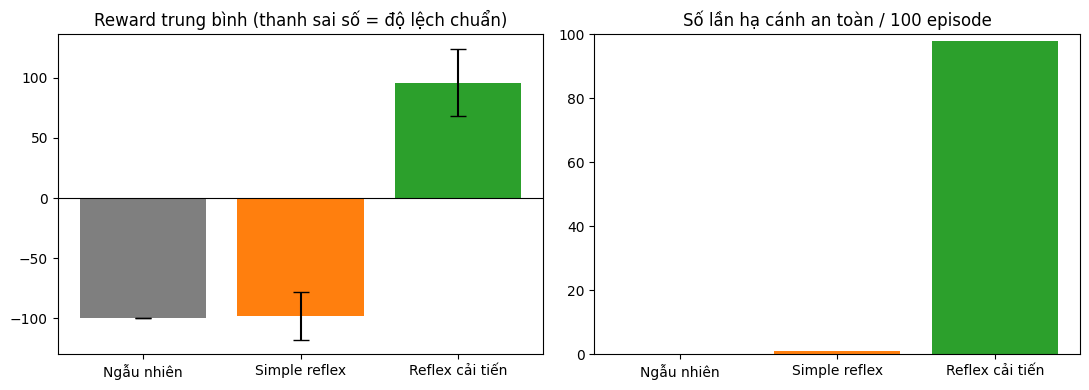

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

env = gym.make("LunarLander-v3", render_mode=None)
np.random.seed(0)

agents = {
    "Ngẫu nhiên": random_agent_function,
    "Simple reflex": rocket_agent_function,
    "Reflex cải tiến": improved_agent_function,
}

rows, all_rewards = [], {}
for name, fn in agents.items():
    rewards = np.array(run_episodes(fn, env, n=100))
    all_rewards[name] = rewards
    rows.append({
        "Tác tử": name,
        "Reward TB": rewards.mean(),
        "Độ lệch chuẩn": rewards.std(),
        "Hạ cánh (+100)": int((rewards == 100).sum()),
        "Rơi (-100)": int((rewards == -100).sum()),
        "Khác (hết giờ)": int(((rewards != 100) & (rewards != -100)).sum()),
    })
env.close()

df = pd.DataFrame(rows).set_index("Tác tử").round(1)
display(df)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
names = list(agents.keys())

ax[0].bar(names, df["Reward TB"], yerr=df["Độ lệch chuẩn"], capsize=6,
          color=["tab:gray", "tab:orange", "tab:green"])
ax[0].set_title("Reward trung bình (thanh sai số = độ lệch chuẩn)")
ax[0].axhline(0, color="black", linewidth=0.8)

ax[1].bar(names, df["Hạ cánh (+100)"], color=["tab:gray", "tab:orange", "tab:green"])
ax[1].set_title("Số lần hạ cánh an toàn / 100 episode")
ax[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()